# Project work 2, Mattia Franchi

In this notebook, I continue my work from project 1. I now read the reservoir statistics from NVE (Magasinstatistikk) directly from the API instead of a CSV file, and I recreate the plots from part 1. I download the cross-border electricity flows between Norway and its six neighbours from the ENTSO-E API for the last two years, write them to a local Cassandra database using Spark, extract them again with Spark, plot the data, and finally store it in MongoDB. My Streamlit app then reads the reservoir data from the NVE API and the cross-border flows from MongoDB.

## Useful Links
- GitHub: https://github.com/m4tti4fr4nchi/ind320-m4tti4fr4nchi
- Streamlit: https://ind320-m4tti4fr4nchi-ybf3fy4znakvdenhn4kked.streamlit.app/
- Video: https://eduumb-my.sharepoint.com/:v:/g/personal/mafra9466_nmbu_no/IQDDsALyJHa8Tb8lkPP9JtjoAQkCmqRxzEQYJtmIlsNAmzo?nav=eyJyZWZlcnJhbEluZm8iOnsicmVmZXJyYWxBcHAiOiJPbmVEcml2ZUZvckJ1c2luZXNzIiwicmVmZXJyYWxBcHBQbGF0Zm9ybSI6IldlYiIsInJlZmVycmFsTW9kZSI6InZpZXciLCJyZWZlcnJhbFZpZXciOiJNeUZpbGVzTGlua0NvcHkifX0&e=fpd5IA

*I hope that the video is available to everyone...better with an @nmbu.no account. Sorry, but Panopto wasn't working*

## Use of AI
In this part I used Claude as an assistant throughout the work when I was facing problems. 
It helped me debug the setup: the MongoDB connection, Spark writing to Cassandra on Windows. It also drafted parts of the markdown explanation (translating to english), which I edited. I ran every cell myself and checked the results, for example that the totals in Cassandra, Spark and MongoDB are identical.
It also helped me bring to life ideas I had for the app, especially regarding the graphic design and user interface.

## Log
The project started from the solid foundation built in the first phase: a Jupyter Notebook reading a local CSV file and a 4-page Streamlit application. The goal of this second step was to evolve the architecture by replacing the static CSV with dynamic API calls, integrating two databases (Cassandra and MongoDB), processing data flows with Apache Spark, and adding a new page to the interface.

Setting up the infrastructure required Cassandra via Docker and Spark configured with Java 17 and winutils on a Windows environment. Technical difficulties were certainly present: the continuous crashes of Spark's Python workers on Windows initially forced me to bypass the problem by using the native driver for data insertion. I had to handle the unreachable Cassandra server when turned off and the Spark session freezing after putting the PC to sleep. MongoDB also presented obstacles related to unauthorized IP and credentials. This phase taught me that an SSL error often hides simple access issues and that the secrets file (secrets.toml) must be strictly excluded from Git.   

When interacting with the NVE API (Magasinstatistikk), I had to handle the absence of specific date parameters, the time formatting based on ISO weeks, and the anomalies of certain areas (like VASS4 having no data). Regarding the ENTSO-E API, a review of my first draft revealed a bug in the timestamps: every value of a period got the same time, so most rows were overwritten. The pie chart confirmed it, showing only about 550 MWh for a whole year. I then expanded the analysis to 6 borders (not limiting it to Sweden), converted the 15-minute data to hourly values in UTC, filled the only missing hour by interpolation, meticulously verifying that the numbers matched at every stage of the pipeline: API, Cassandra, Spark, and finally MongoDB.

The web application underwent a profound reorganization. I centralized the common code into a modules/ folder and used session_state to keep shared controls active while navigating between pages. Now, the table displays transposed data (one row per column) with a dedicated chart for each area. For the new Page 4, I implemented st.columns, st.pills, and Plotly, adding the cross-border connections filter. During development, I optimized the User Experience by moving the controls from the sidebar directly into the page body and setting a wide horizontal layout. This process made me fully understand how the cache works to optimize loading times and why some rows in the table initially seemed identical.   

The biggest challenge was undoubtedly stabilizing Spark on Windows. Later I solved it by sending the data to Spark through Apache Arrow, so the insertion into Cassandra is now done with Spark as required.
Overall, building a real interconnected data pipeline was the most useful part of the project. In hindsight, I would do two things differently: I would immediately verify the numerical totals after each extraction and make sure to correctly close the Spark session before putting the computer to sleep.

## 1. Database setup and connection tests

### Local database: Cassandra. Test that your Spark-Cassandra connection works.
Cassandra runs locally in a Docker container and Spark uses the DataStax connector (Java 17, pyspark 3.5.1 and the winutils drivers for Windows, as described in the book). The first cell checks the connection with the Python driver; the last cell asks Spark to list the keyspaces and tables through the Cassandra catalog, which only works if Spark can talk to Cassandra.

In [7]:
from cassandra.cluster import Cluster

# 1) Direct connection with the Python driver (Cassandra runs locally in Docker)
cluster = Cluster(["localhost"], port=9042)
session = cluster.connect()
version = session.execute("SELECT release_version FROM system.local").one().release_version
print("Connected to Cassandra, version", version)

Connected to Cassandra, version 5.0.9


In [8]:
import os
import sys
from pyspark.sql import SparkSession

# Java 17 (JAVA_HOME) and winutils (HADOOP_HOME=C:\Hadoop) are already set system-wide on this PC
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["PYSPARK_HADOOP_VERSION"] = "without"

spark = SparkSession.builder.appName("IND320_ProjectWork2") \
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1") \
    .config("spark.cassandra.connection.host", "localhost") \
    .config("spark.cassandra.connection.port", "9042") \
    .config("spark.sql.extensions", "com.datastax.spark.connector.CassandraSparkExtensions") \
    .config("spark.sql.catalog.mycatalog", "com.datastax.spark.connector.datasource.CassandraCatalog") \
    .config("spark.sql.session.timeZone", "UTC") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true") \
    .config("spark.sql.execution.arrow.pyspark.fallback.enabled", "false") \
    .getOrCreate()
print("Spark", spark.version, "is running.")

Spark 3.5.1 is running.


In [9]:
# 2) Spark reads from Cassandra through the DataStax connector: list keyspaces and tables via the Cassandra catalog
spark.sql("SHOW NAMESPACES IN mycatalog").show()
spark.sql("SHOW TABLES IN mycatalog.ind320").show()

+-----------------+
|        namespace|
+-----------------+
|    test_keyspace|
|           ind320|
|my_first_keyspace|
+-----------------+

+---------+------------------+-----------+
|namespace|         tableName|isTemporary|
+---------+------------------+-----------+
|   ind320|cross_border_flows|      false|
+---------+------------------+-----------+



### Remote database: MongoDB. Test that you can manipulate data from Python.
The connection string is stored in `.streamlit/secrets.toml`, which is excluded from Git, so no password appears in the notebook or on GitHub. The test inserts, reads, updates and deletes documents in a separate `connection_test` collection and drops it at the end, so the real data are never touched.

In [10]:
import tomllib
from pymongo import MongoClient

# The connection string is read from the local secrets file (never written in the notebook)
with open("../.streamlit/secrets.toml", "rb") as f:
    secrets = tomllib.load(f)
mongo_client = MongoClient(secrets["mongo"]["uri"])
mongo_client.admin.command("ping")
print("Connected to MongoDB.")

# Create, read, update and delete documents in a separate test collection
test = mongo_client["ind320"]["connection_test"]
test.insert_many([{"connection": "NO-SE", "quantity_mw": 1000.0},
                  {"connection": "NO-DE", "quantity_mw": 1400.0}])
print("Inserted:", list(test.find({}, {"_id": 0})))

test.update_one({"connection": "NO-DE"}, {"$set": {"quantity_mw": 1200.0}})
print("Updated: ", test.find_one({"connection": "NO-DE"}, {"_id": 0}))

test.delete_many({})
print("Documents left after delete:", test.count_documents({}))
test.drop()  # remove the empty test collection

Connected to MongoDB.
Inserted: [{'connection': 'NO-SE', 'quantity_mw': 1000.0}, {'connection': 'NO-DE', 'quantity_mw': 1400.0}]
Updated:  {'connection': 'NO-DE', 'quantity_mw': 1200.0}
Documents left after delete: 0


## 2. Reservoir statistics from the NVE API

### Remove your CSV-file for the Magasinstatistikk and use a direct API connection instead.
Recreate the associated plots from part 1 of the project using the API connection.
The data now come from the public NVE endpoint `HentOffentligData`, which returns the whole history as JSON in one request (it has no date parameters). The JSON is loaded directly into a Pandas DataFrame with the same structure as the old CSV file.

In [11]:
import pandas as pd
import requests

# Set the URL endpoint for the NVE Magasinstatistikk public data API
api_url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

# Execute an HTTP GET request to retrieve the data
# As seen in the professor's examples (e.g., REST API notebook), we use the requests library.
response = requests.get(api_url)

# Verify if the connection was successful (HTTP status code 200 means OK)
if response.status_code == 200:
    # Directly parse the JSON response into a Pandas DataFrame
    df = pd.DataFrame(response.json())
    print("Data successfully retrieved from the NVE API!")
else:
    print(f"Error fetching data. HTTP Status Code: {response.status_code}")

# Display the initial structure of the downloaded DataFrame
df.head()

Data successfully retrieved from the NVE API!


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


### (FROM: pw_1) Rename headers to English and understandable
After renaming, the `date` column is converted from text to datetime and the rows are sorted by area and date.


In [12]:
# Define a dictionary to map the original Norwegian column names to English
translate = {
    'dato_Id': 'date',
    'omrType': 'area_type',
    'omrnr': 'area_number',
    'iso_aar': 'year',
    'iso_uke': 'week',
    'fyllingsgrad': 'filling_rate',
    'kapasitet_TWh': 'capacity_twh',
    'fylling_TWh': 'filling_twh',
    'neste_Publiseringsdato': 'next_publish_date',
    'fyllingsgrad_forrige_uke': 'filling_rate_last_week',
    'endring_fyllingsgrad': 'filling_rate_change'
}

#apply the new column names to the dataframe
df = df.rename(columns=translate)

# Convert the date column to real datetimes (it arrives as text from the API) and sort chronologically
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["area_type", "area_number", "date"]).reset_index(drop=True)

#print the first few rows of the dataframe to verify the changes
df.head()


,date,area_type,area_number,year,week,filling_rate,capacity_twh,filling_twh,next_publish_date,filling_rate_last_week,filling_rate_change
0,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869
1,1995-01-15,EL,1,1995,2,0.579205,6.003264,3.477117,0001-01-01T00:00:00,0.617574,-0.038369
2,1995-01-22,EL,1,1995,3,0.546713,6.003264,3.282063,0001-01-01T00:00:00,0.579205,-0.032491
3,1995-01-29,EL,1,1995,4,0.504545,6.003264,3.028916,0001-01-01T00:00:00,0.546713,-0.042168
4,1995-02-05,EL,1,1995,5,0.465335,6.003264,2.793528,0001-01-01T00:00:00,0.504545,-0.039210


### Identify the areas of Norway covered by the API
The API uses three types of areas: **NO** (the whole country, area 0), **EL** (the five electricity price areas NO1-NO5) and **VASS** (river basins). The area endpoint lists four river basins, but the statistics only contain data for VASS1-VASS3: VASS4 (Northern Norway) has no data. These three area types are the options of the radio buttons in the Streamlit app.

In [ ]:
# The NVE API has a separate endpoint (HentOmråder = "get areas") that describes every area used in the statistics
areas_url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOmr%C3%A5der"  # "å" written URL-encoded
areas_json = requests.get(areas_url, timeout=60).json()[0]  # {"land": [...], "elspot": [...], "vassdrag": [...]}
areas = pd.concat([pd.DataFrame(group) for group in areas_json.values()], ignore_index=True)
areas = areas.rename(columns={"omrType": "area_type", "omrnr": "area_number",
                              "navn": "name", "beskrivelse": "description"})

# Count how many weeks of data the statistics endpoint actually contains for each area
weeks = df.groupby(["area_type", "area_number"]).size().rename("weeks_of_data").reset_index()
areas = areas.merge(weeks, on=["area_type", "area_number"], how="left")
areas[["area_type", "area_number", "name", "description", "weeks_of_data"]]

,area_type,area_number,name,description,weeks_of_data
0,NO,0,Norge,Hele landet,1658.0
1,EL,1,NO 1,Sørøst-Norge. Omfatter østlige del av Østlande...,1658.0
2,EL,2,NO 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...,1658.0
3,EL,3,NO 3,Midt-Norge. Omfatter nordre og vestlige del av...,1658.0
4,EL,4,NO 4,Nord-Norge. Omfatter resten av Trøndelag og No...,1658.0
5,EL,5,NO 5,Vest-Norge. Omfatter midtre del av Vestland op...,1658.0
6,VASS,1,VASS1,"Sørøst-Norge. Østlandet, Agder og deler av Rog...",1658.0
7,VASS,2,VASS2,Vest-Norge. Resten av Rogaland og Vestland.,1658.0
8,VASS,3,VASS3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl...",1658.0
9,VASS,4,VASS4,Nord-Norge. Resten av Nordland og nordover.,NaN


### Time columns: experience from part 1
In part 1 the dates arrived as text and had to be converted. A closer look shows three more pitfalls: every date is a Sunday (one row per ISO week), `year` and `week` follow the ISO calendar, so the first days of January can belong to the previous year, and `next_publish_date` uses 0001-01-01 as a placeholder, which Pandas cannot store as a datetime. For these reasons the app filters on `date`, not on `year`, and `next_publish_date` is left as text.

In [31]:
# 1) Every date is a Sunday: the data has one row per area and ISO week, dated at the end of the week
print("Weekdays found in 'date':", df["date"].dt.day_name().unique())

# 2) 'year' and 'week' are ISO-week numbers, so the first days of January can belong to week 52/53 of the year before.
#    Filtering on 'date' (as the Streamlit app does) avoids mixing up years.
iso_mismatch = df[df["year"] != df["date"].dt.year]
print(f"Rows where the ISO year differs from the calendar year: {len(iso_mismatch)}")
display(iso_mismatch[["date", "year", "week"]].drop_duplicates().sort_values("date").head())

# 3) 'next_publish_date' uses 0001-01-01 as a placeholder for "not set", a date pandas cannot store as datetime
placeholder = (df["next_publish_date"] == "0001-01-01T00:00:00").sum()
print(f"Rows with the placeholder next_publish_date 0001-01-01: {placeholder} of {len(df)}")

Weekdays found in 'date': <ArrowStringArray>
['Sunday']
Length: 1, dtype: str
Rows where the ISO year differs from the calendar year: 108


,date,year,week
208,1999-01-03,1998,53
260,2000-01-02,1999,52
521,2005-01-02,2004,53
573,2006-01-01,2005,52
782,2010-01-03,2009,53


Rows with the placeholder next_publish_date 0001-01-01: 11322 of 14922


### (FROM: pw_1) Print its contents in a relevant way
Printing the dataset structure and a statistical summary to understand data types, missing values, and the general distribution of the numerical metrics.

In [13]:
df.info()
df.describe().round(2).T #Rounded to 2 decimal places and transposed for better readability

<class 'pandas.DataFrame'>
RangeIndex: 14922 entries, 0 to 14921
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   date                    14922 non-null  datetime64[us]
 1   area_type               14922 non-null  str           
 2   area_number             14922 non-null  int64         
 3   year                    14922 non-null  int64         
 4   week                    14922 non-null  int64         
 5   filling_rate            14922 non-null  float64       
 6   capacity_twh            14922 non-null  float64       
 7   filling_twh             14922 non-null  float64       
 8   next_publish_date       14922 non-null  str           
 9   filling_rate_last_week  14922 non-null  float64       
 10  filling_rate_change     14922 non-null  float64       
dtypes: datetime64[us](1), float64(5), int64(3), str(2)
memory usage: 1.6 MB


,count,mean,min,25%,50%,75%,max,std
date,14922,2010-11-24 12:00:00,1995-01-08 00:00:00,2002-12-15 00:00:00,2010-11-24 12:00:00,2018-11-04 00:00:00,2026-10-11 00:00:00,NaN
area_number,14922.0,2.33,0.0,1.0,2.0,3.0,5.0,1.49
year,14922.0,2010.39,1995.0,2002.0,2010.0,2018.0,2026.0,9.17
week,14922.0,26.44,1.0,13.0,26.0,39.0,53.0,15.01
filling_rate,14922.0,0.62,0.05,0.46,0.65,0.8,1.02,0.21
capacity_twh,14922.0,29.15,6.0,17.39,23.24,34.04,87.44,22.74
filling_twh,14922.0,18.14,0.31,7.33,14.5,22.2,84.52,15.96
filling_rate_last_week,14922.0,0.62,0.05,0.46,0.65,0.8,1.02,0.21
filling_rate_change,14922.0,0.0,-0.24,-0.02,-0.01,0.02,0.35,0.03


### (FROM: pw_1) Plot each column separately
Plotting each numeric column separately over time to identify distinct patterns, seasonalities, and overall trends across the dataset.
Compared to part 1, the national series is now taken from the area type NO, which NVE already provides as the total for Norway. Averaging all rows of a date would mix the whole country, the price areas and the river basins.

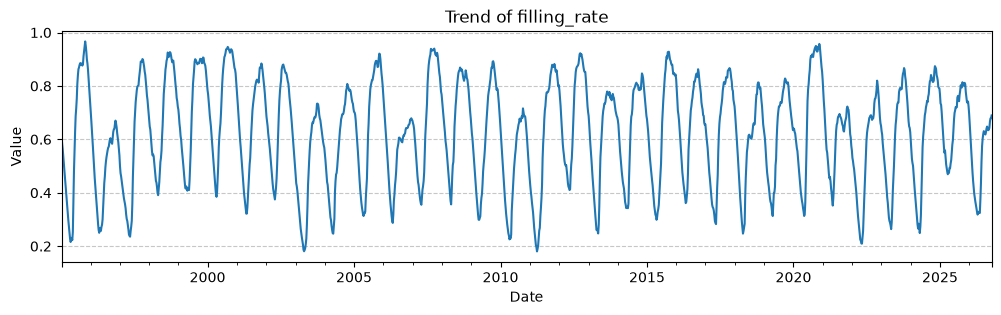

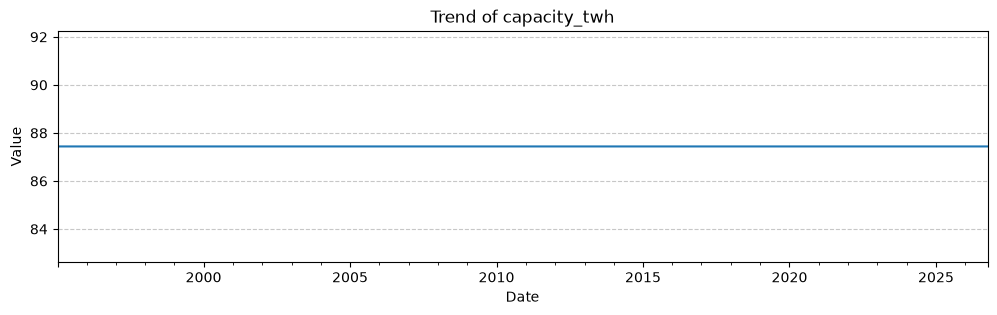

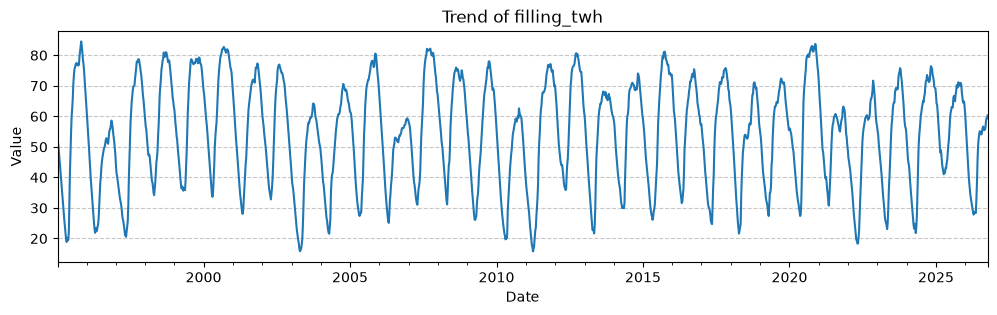

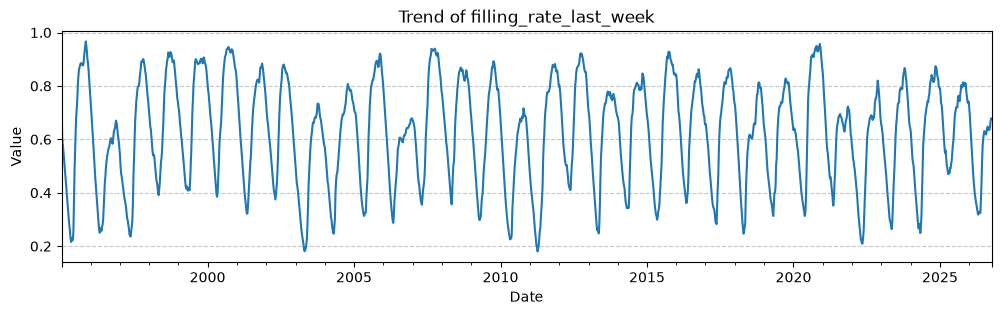

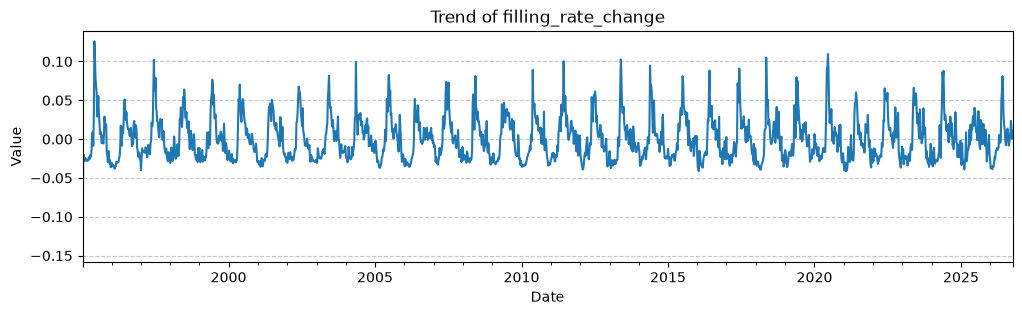

In [14]:
import matplotlib.pyplot as plt

numeric_columns = ["filling_rate", "capacity_twh", "filling_twh", "filling_rate_last_week", "filling_rate_change"]
df_national = df[df["area_type"] == "NO"].set_index("date")[numeric_columns]

for col in numeric_columns: 
    plt.figure(figsize=(12, 3))
    df_national[col].plot(linewidth=1.5, color='#1f77b4')
    plt.title(f"Trend of {col}")
    plt.ylabel("Value")
    plt.xlabel("Date")
    plt.grid(axis='y', linestyle='--', alpha=0.7) #adds horizontal grid lines to read values easier
    plt.show()

    

### (FROM: pw_1) Plot all columns together. Consider how to make this natural, given that the scales are different.
To visualize all metrics on a single chart naturally, I had to consider the vastly different scales (e.g., total capacity in TWh vs. filling rate in percentages). I apply a **Min-Max Normalization** to rescale all physical metrics to a proportional 0.0 - 1.0 range, allowing for a direct visual comparison of their trends. Structural columns like `year` and `week` are intentionally excluded to focus solely on the physical reservoir dynamics.

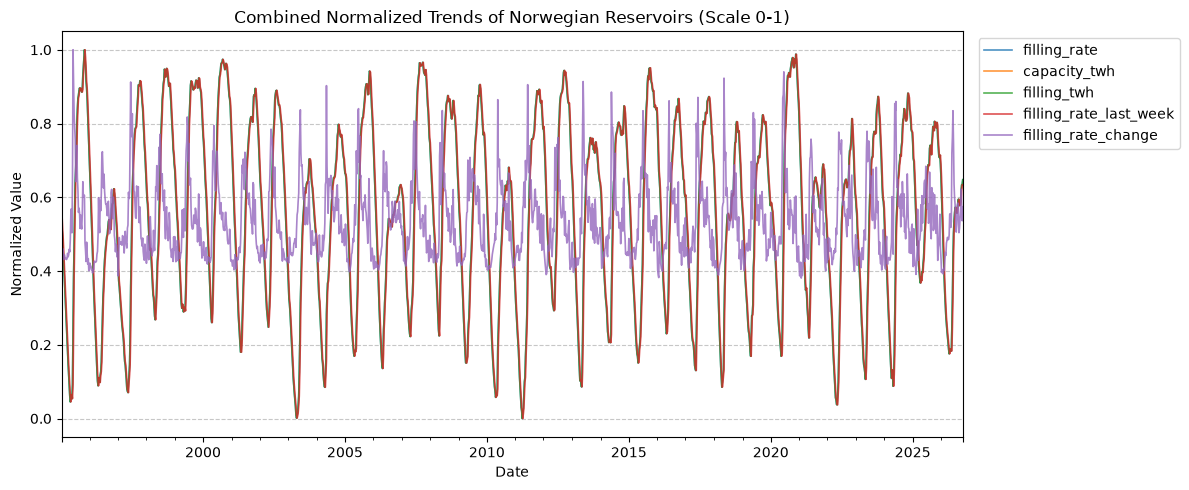

In [15]:
cols_to_drop = ['year', 'week', 'area_number'] # Isolate only the relevant physical metrics, dropping structural columns like year or week
metrics_df = df_national.drop(columns=cols_to_drop, errors='ignore')

df_normalized = (metrics_df - metrics_df.min()) / (metrics_df.max() - metrics_df.min()) #min-max normalization formula applied to each column
#now I have a new dataframe with all the columns normalized between 0 and 1

plt.figure(figsize=(12, 5)) #here I create a new figure with a specific size to accommodate the combined plot of all normalized metrics
df_normalized.plot(ax=plt.gca(), linewidth=1.2, alpha=0.8)

plt.title("Combined Normalized Trends of Norwegian Reservoirs (Scale 0-1)")
plt.ylabel("Normalized Value")
plt.xlabel("Date")

plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left') #i created an external legend to be able to read all the metrics without overlapping the plot
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout() #avoid overlapping of the plot with the legend and other elements
plt.show()

## 3. Cross-border flows from the ENTSO-E API

### Use the ENTSO-E API to retrieve cross-border transfer data from/to Norway for the last two years.
I download the *physical flows* (document type A11) for all six connections of Norway (Sweden, Denmark, Finland, Germany, the Netherlands and Great Britain), in both directions. ENTSO-E allows at most one year per request, so the two years are split into two windows. The XML gives each value as a position inside a period, so the time of each point is computed as `start + (position - 1) × resolution`. Some series have 15-minute resolution: all data are averaged to hourly values, so one row is the energy in MWh for that hour. Times are kept in UTC to avoid daylight-saving gaps. A summary table checks the number of hours, missing values and peaks (which match the cable capacities), and the only missing hour (NO-FI export) is filled by linear interpolation.

In [ ]:
import tomllib
import time
import requests
import xml.etree.ElementTree as ET
import pandas as pd

# Read the ENTSO-E token from the local secrets file (kept out of Git)
with open("../.streamlit/secrets.toml", "rb") as f:
    secrets = tomllib.load(f)
entsoe_token = secrets["entsoe"]["api_token"]

# Norway and its neighbours with a physical interconnector (EIC area codes)
NORWAY = "10YNO-0--------C"
NEIGHBOURS = {
    "SE": "10YSE-1--------K",  # Sweden
    "DK": "10Y1001A1001A65H",  # Denmark 
    "FI": "10YFI-1--------U",  # Finland
    "DE": "10Y1001A1001A83F",  # Germany 
    "NL": "10YNL----------L",  # Netherlands 
    "GB": "10YGB----------A",  # Great Britain 
}

# ENTSO-E allows at most one year per request, so the last two years are split in two windows (UTC)
end = pd.Timestamp.now(tz="UTC").floor("h")
windows = [
    (end - pd.Timedelta(days=730), end - pd.Timedelta(days=365)),
    (end - pd.Timedelta(days=365), end),
]
print("Download period:", windows[0][0], "->", windows[1][1])

Download period: 2024-10-15 15:00:00+00:00 -> 2026-10-15 15:00:00+00:00


In [17]:
RESOLUTIONS = {"PT15M": pd.Timedelta(minutes=15), "PT30M": pd.Timedelta(minutes=30), "PT60M": pd.Timedelta(hours=1)}


def fetch_flows(in_domain, out_domain, start, stop):
    """Download physical cross-border flows (document type A11) as XML text."""
    params = {
        "securityToken": entsoe_token,
        "documentType": "A11",
        "in_Domain": in_domain,    # area receiving the energy
        "out_Domain": out_domain,  # area sending the energy
        "periodStart": start.strftime("%Y%m%d%H00"),
        "periodEnd": stop.strftime("%Y%m%d%H00"),
    }
    response = requests.get("https://web-api.tp.entsoe.eu/api", params=params, timeout=60)
    if response.status_code != 200 or "Acknowledgement_MarketDocument" in response.text[:300]:
        return None  # no data for this border/period
    return response.text


def parse_flows(xml_text):
    """Turn an A11 XML document into an hourly time series (MW)."""
    root = ET.fromstring(xml_text)
    frames = []
    for period in root.findall(".//{*}Period"):
        start = pd.Timestamp(period.find("{*}timeInterval/{*}start").text)
        stop = pd.Timestamp(period.find("{*}timeInterval/{*}end").text)
        step = RESOLUTIONS[period.find("{*}resolution").text]
        values = {int(p.find("{*}position").text): float(p.find("{*}quantity").text)
                  for p in period.findall("{*}Point")}
        # Each point's time is start + (position - 1) * resolution; missing positions repeat the previous value
        n = int((stop - start) / step)
        series = pd.Series(values).reindex(range(1, n + 1)).ffill()
        series.index = start + (series.index - 1) * step
        frames.append(series)
    if not frames:
        return None
    # Harmonise 15-minute and hourly data to hourly averages (MW averaged over one hour = MWh)
    return pd.concat(frames).resample("1h").mean()

In [18]:
frames = []
for country, code in NEIGHBOURS.items():
    for direction, (in_domain, out_domain) in {"import": (NORWAY, code), "export": (code, NORWAY)}.items():
        parts = []
        for start, stop in windows:
            xml_text = fetch_flows(in_domain, out_domain, start, stop)
            series = parse_flows(xml_text) if xml_text else None
            if series is not None:
                parts.append(series)
            time.sleep(0.5)  # be gentle with the API
        if not parts:
            print(f"NO-{country} {direction}: no data")
            continue
        series = pd.concat(parts).groupby(level=0).mean()  # drop overlap between the two windows
        part = series.rename("quantity_mw").rename_axis("timestamp").reset_index()
        part["connection"] = f"NO-{country}"
        part["direction"] = direction
        frames.append(part)
        print(f"NO-{country} {direction}: {len(part)} hourly rows")

flows = pd.concat(frames, ignore_index=True)
flows["timestamp"] = flows["timestamp"].dt.tz_convert(None)  # naive UTC, as expected by Spark/Cassandra
flows = flows[["connection", "direction", "timestamp", "quantity_mw"]]

flows.groupby(["connection", "direction"]).agg(
    rows=("quantity_mw", "size"),                          # hours in the period (always 17520)
    missing=("quantity_mw", lambda s: s.isna().sum()),     # hours without any value from the API
    zero_hours=("quantity_mw", lambda s: (s == 0).sum()),  # hours with no flow in this direction
    first=("timestamp", "min"),
    last=("timestamp", "max"),
    mean_mw=("quantity_mw", "mean"),
    max_mw=("quantity_mw", "max"),
)

NO-SE import: 17520 hourly rows
NO-SE export: 17520 hourly rows
NO-DK import: 17520 hourly rows
NO-DK export: 17520 hourly rows
NO-FI import: 17520 hourly rows
NO-FI export: 17520 hourly rows
NO-DE import: 17520 hourly rows
NO-DE export: 17520 hourly rows
NO-NL import: 17520 hourly rows
NO-NL export: 17520 hourly rows
NO-GB import: 17520 hourly rows
NO-GB export: 17520 hourly rows


rows  missing  zero_hours               first  \
connection direction                                                   
NO-DE      export     17520        0        3481 2024-10-15 15:00:00   
           import     17520        0       12971 2024-10-15 15:00:00   
NO-DK      export     17520        0        3889 2024-10-15 15:00:00   
           import     17520        0       12190 2024-10-15 15:00:00   
NO-FI      export     17520        1        3913 2024-10-15 15:00:00   
           import     17520        0       12772 2024-10-15 15:00:00   
NO-GB      export     17520        0        2894 2024-10-15 15:00:00   
           import     17520        0       15047 2024-10-15 15:00:00   
NO-NL      export     17520        0        8226 2024-10-15 15:00:00   
           import     17520        0       14233 2024-10-15 15:00:00   
NO-SE      export     17520        0        3226 2024-10-15 15:00:00   
           import     17520        0        2556 2024-10-15 15:00:00   

                                    last     mean_mw       max_mw  
connection direction                                               
NO-DE      export    2026-10-15 14:00:00  775.276854  1406.520000  
           import    2026-10-15 14:00:00  176.661106  1445.232750  
NO-DK      export    2026-10-15 14:00:00  797.138802  1677.130000  
           import    2026-10-15 14:00:00  227.578953  1610.240967  
NO-FI      export    2026-10-15 14:00:00   34.569967   115.260000  
           import    2026-10-15 14:00:00    5.016414   100.020000  
NO-GB      export    2026-10-15 14:00:00  998.438784  1472.870000  
           import    2026-10-15 14:00:00  104.429368  1397.766513  
NO-NL      export    2026-10-15 14:00:00  259.119935   676.062500  
           import    2026-10-15 14:00:00   66.438400   687.610000  
NO-SE      export    2026-10-15 14:00:00  486.528069  3564.050000  
           import    2026-10-15 14:00:00  993.717959  4353.100000

In [19]:
# Data quality: one missing hour (NO-FI export) is filled by linear interpolation within its own series
flows = flows.sort_values(["connection", "direction", "timestamp"]).reset_index(drop=True)
flows["quantity_mw"] = flows.groupby(["connection", "direction"])["quantity_mw"].transform(lambda s: s.interpolate())
print("Missing values left:", flows["quantity_mw"].isna().sum())

Missing values left: 0


### Insert the data into Cassandra using Spark.
The table uses `(connection, direction)` as partition key and `timestamp` as clustering key, so each series is stored together and each hour is one unique row: re-running the insert overwrites instead of duplicating. The table is truncated first, so it holds exactly the downloaded two-year window. The Pandas DataFrame is sent to Spark with Apache Arrow enabled: this avoids the Python worker processes that crashed on Windows in my first attempt. The last cell reads the table back and counts the rows per series.

In [ ]:
from cassandra.cluster import Cluster

cluster = Cluster(["localhost"], port=9042)
session = cluster.connect()

session.execute("""
    CREATE KEYSPACE IF NOT EXISTS ind320
    WITH REPLICATION = {'class': 'SimpleStrategy', 'replication_factor': 1}
""")

# Partition key (connection, direction): each series is stored together and queried quickly.
# Clustering key timestamp: one row per hour, so re-running the insert overwrites instead of duplicating.
session.execute("""
    CREATE TABLE IF NOT EXISTS ind320.cross_border_flows (
        connection text,
        direction text,
        timestamp timestamp,
        quantity_mw double,
        PRIMARY KEY ((connection, direction), timestamp)
    )
""")
# Start from an empty table so that it holds exactly the two-year window downloaded above
session.execute("TRUNCATE ind320.cross_border_flows")
print("Keyspace 'ind320' and table 'cross_border_flows' are ready.")

Keyspace 'ind320' and table 'cross_border_flows' are ready.


In [21]:
flows_spark = spark.createDataFrame(flows)

flows_spark.write.format("org.apache.spark.sql.cassandra") \
    .options(table="cross_border_flows", keyspace="ind320") \
    .mode("append") \
    .save()
print(f"{flows_spark.count()} rows written to Cassandra through Spark.")

210240 rows written to Cassandra through Spark.


In [22]:
check = spark.read.format("org.apache.spark.sql.cassandra") \
    .options(table="cross_border_flows", keyspace="ind320").load()
check.groupBy("connection", "direction").count().orderBy("connection", "direction").show()

+----------+---------+-----+
|connection|direction|count|
+----------+---------+-----+
|     NO-DE|   export|17542|
|     NO-DE|   import|17542|
|     NO-DK|   export|17542|
|     NO-DK|   import|17542|
|     NO-FI|   export|17542|
|     NO-FI|   import|17542|
|     NO-GB|   export|17542|
|     NO-GB|   import|17542|
|     NO-NL|   export|17542|
|     NO-NL|   import|17542|
|     NO-SE|   export|17542|
|     NO-SE|   import|17542|
+----------+---------+-----+



### Use Spark to extract relevant columns from Cassandra.
As in the book, the Cassandra table is loaded into Spark and registered as a temporary view. A Spark SQL query keeps the columns needed for the plots and adds `year` and `month`, so the plots can filter directly in Spark and only bring small results to Pandas.

In [23]:
from pyspark.sql import functions as F

# Read the table through the Spark-Cassandra connector and register it as a view (as in the course book)
spark.read.format("org.apache.spark.sql.cassandra") \
    .options(table="cross_border_flows", keyspace="ind320").load() \
    .createOrReplaceTempView("flows_view")

# Keep the columns needed by the plots and derive year/month for filtering (UTC)
flows_extracted = spark.sql("""
    SELECT connection, direction, timestamp,
           year(timestamp)  AS year,
           month(timestamp) AS month,
           quantity_mw
    FROM flows_view
""")
flows_extracted.printSchema()
flows_extracted.orderBy("connection", "direction", "timestamp").show(5)

root
 |-- connection: string (nullable = false)
 |-- direction: string (nullable = false)
 |-- timestamp: timestamp (nullable = true)
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- quantity_mw: double (nullable = true)

+----------+---------+-------------------+----+-----+------------------+
|connection|direction|          timestamp|year|month|       quantity_mw|
+----------+---------+-------------------+----+-----+------------------+
|     NO-DE|   export|2024-10-14 17:00:00|2024|   10|            1404.8|
|     NO-DE|   export|2024-10-14 18:00:00|2024|   10|            1404.8|
|     NO-DE|   export|2024-10-14 19:00:00|2024|   10|           1404.72|
|     NO-DE|   export|2024-10-14 20:00:00|2024|   10|           1395.24|
|     NO-DE|   export|2024-10-14 21:00:00|2024|   10|1191.6399999999999|
+----------+---------+-------------------+----+-----+------------------+
only showing top 5 rows



### A pie chart for the total production of one year from a chosen connection, where each piece of the pie is the amount in and out of Norway.
I chose the connection NO-DE (NordLink) and 2025, the only complete calendar year in the two-year window. Summing hourly MW values over a year gives MWh, shown in GWh. In 2025 about 91 % of the energy on this cable went out of Norway.

           energy_mwh  energy_gwh
direction                        
import       766714.6       766.7
export      7787854.6      7787.9


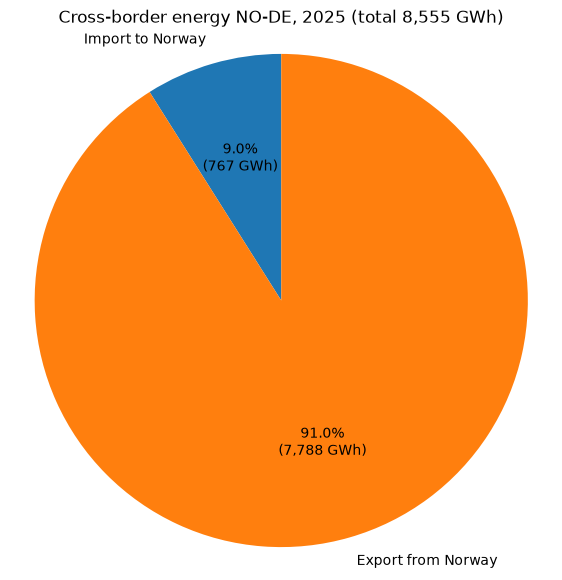

In [24]:
import matplotlib.pyplot as plt

pie_connection = "NO-DE"  # choose any of: NO-SE, NO-DK, NO-FI, NO-DE, NO-NL, NO-GB
pie_year = 2025           # the only complete calendar year in the two-year window

# Each row is an hourly average in MW, so summing the rows of a year gives energy in MWh
pie_data = flows_extracted \
    .filter((F.col("connection") == pie_connection) & (F.col("year") == pie_year)) \
    .groupBy("direction") \
    .agg(F.sum("quantity_mw").alias("energy_mwh")) \
    .toPandas() \
    .set_index("direction")
pie_data["energy_gwh"] = pie_data["energy_mwh"] / 1000
print(pie_data.round(1))

labels = {"import": "Import to Norway", "export": "Export from Norway"}
colours = {"import": "#1f77b4", "export": "#ff7f0e"}
total_gwh = pie_data["energy_gwh"].sum()

plt.figure(figsize=(7, 7))
plt.pie(
    pie_data["energy_gwh"],
    labels=[labels[d] for d in pie_data.index],
    colors=[colours[d] for d in pie_data.index],
    autopct=lambda p: f"{p:.1f}%\n({p * total_gwh / 100:,.0f} GWh)",
    startangle=90,
)
plt.title(f"Cross-border energy {pie_connection}, {pie_year} (total {total_gwh:,.0f} GWh)")
plt.axis("equal")
plt.show()

### A line plot for the first month of a year for a chosen connection. Make separate lines for each connection and direction.
The task mentions both "a chosen connection" and "separate lines for each connection and direction". I plot all six connections for January 2026, one colour per connection, with solid lines for import and dashed lines for export. In the Streamlit app the connections can be filtered.

connection  direction
NO-DE       export       744
            import       744
NO-DK       export       744
            import       744
NO-FI       export       744
            import       744
NO-GB       export       744
            import       744
NO-NL       export       744
            import       744
NO-SE       export       744
            import       744
dtype: int64


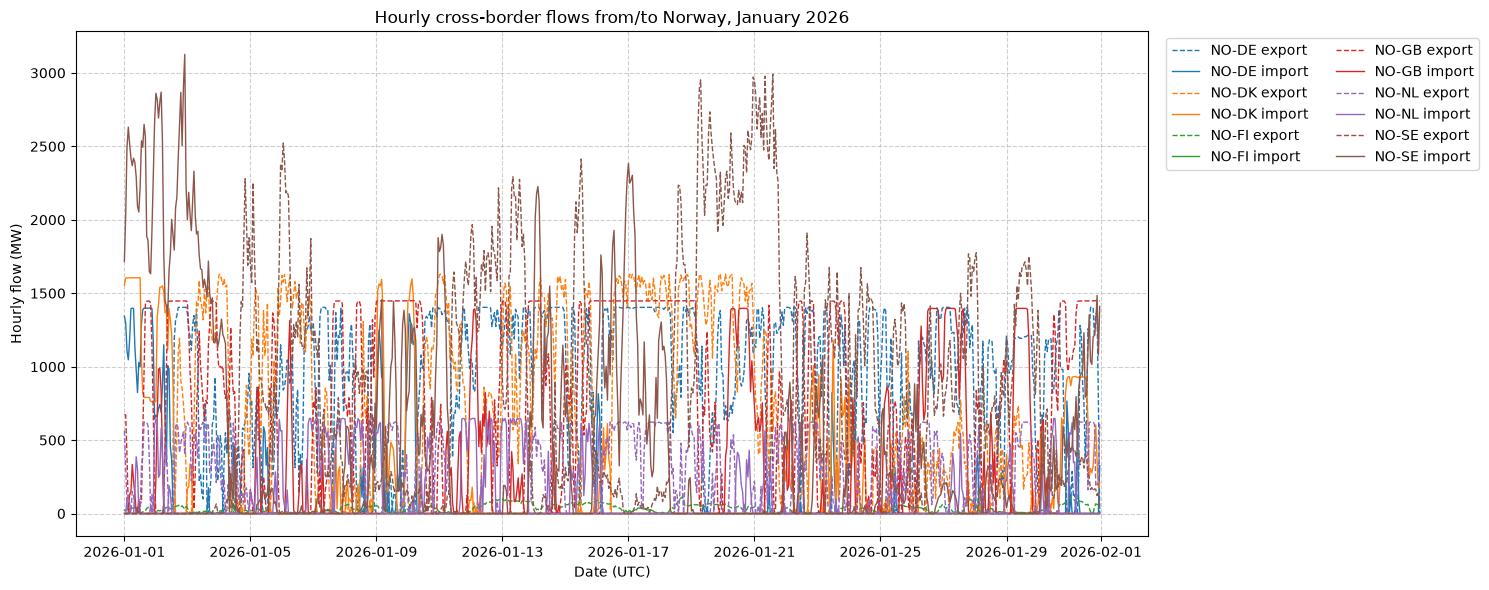

In [25]:
line_year = 2026  # January of the most recent year

# Filter in Spark, then bring only one month (~9,000 rows) to pandas for plotting
line_data = flows_extracted \
    .filter((F.col("year") == line_year) & (F.col("month") == 1)) \
    .select("connection", "direction", "timestamp", "quantity_mw") \
    .orderBy("connection", "direction", "timestamp") \
    .toPandas()
print(line_data.groupby(["connection", "direction"]).size())

# One colour per connection, solid line = import, dashed line = export
connection_colours = dict(zip(sorted(line_data["connection"].unique()), plt.cm.tab10.colors))
line_styles = {"import": "-", "export": "--"}

fig, ax = plt.subplots(figsize=(15, 6))
for (connection, direction), group in line_data.groupby(["connection", "direction"]):
    ax.plot(group["timestamp"], group["quantity_mw"],
            color=connection_colours[connection], linestyle=line_styles[direction],
            linewidth=1, label=f"{connection} {direction}")
ax.set_title(f"Hourly cross-border flows from/to Norway, January {line_year}")
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Hourly flow (MW)")
ax.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Insert the Spark-extracted data into your MongoDB.
The Spark-extracted data are converted to a list of dictionaries (documents) and inserted with `insert_many`. The collection is emptied first, because MongoDB has no primary key that would prevent duplicates. The second cell checks with MongoDB aggregations that the counts and the pie-chart totals are identical to Cassandra and Spark.

In [ ]:
from pymongo import MongoClient

# Connection string from the same local secrets file used for the ENTSO-E token
mongo_client = MongoClient(secrets["mongo"]["uri"])
mongo_client.admin.command("ping")
collection = mongo_client["ind320"]["cross_border_flows"]

# The Spark-extracted data (section 5) are converted to a list of dictionaries, i.e. MongoDB documents
documents = flows_extracted.toPandas().to_dict("records")

# Start from an empty collection so that re-running the cell does not create duplicates
collection.delete_many({})
result = collection.insert_many(documents, ordered=False)

print(f"{len(result.inserted_ids)} documents inserted into MongoDB.")

210504 documents inserted into MongoDB.


In [27]:
# 1) Every series should have the same number of documents as in Cassandra
counts = collection.aggregate([
    {"$group": {"_id": {"connection": "$connection", "direction": "$direction"}, "documents": {"$sum": 1}}},
    {"$sort": {"_id.connection": 1, "_id.direction": 1}},
])
for row in counts:
    print(row["_id"]["connection"], row["_id"]["direction"], row["documents"])

# 2) Recompute the pie-chart totals directly in MongoDB: they must match section 6
pie_check = collection.aggregate([
    {"$match": {"connection": pie_connection, "year": pie_year}},
    {"$group": {"_id": "$direction", "energy_gwh": {"$sum": {"$divide": ["$quantity_mw", 1000]}}}},
])
for row in pie_check:
    print(f"{pie_connection} {pie_year} {row['_id']}: {row['energy_gwh']:,.1f} GWh")

NO-DE export 17542
NO-DE import 17542
NO-DK export 17542
NO-DK import 17542
NO-FI export 17542
NO-FI import 17542
NO-GB export 17542
NO-GB import 17542
NO-NL export 17542
NO-NL import 17542
NO-SE export 17542
NO-SE import 17542
NO-DE 2025 import: 766.7 GWh
NO-DE 2025 export: 7,787.9 GWh


## 4. Closing the connections
Spark, Cassandra and MongoDB connections are closed at the end. This also matters in practice: when the PC went to sleep with Spark running, the Spark session died and had to be restarted.

In [28]:
mongo_client.close()
cluster.shutdown()
spark.stop()
print("All connections closed and Spark stopped.")

All connections closed and Spark stopped.
